# Hotspots: noise calls by block

**A8.** Are noise complaints concentrated in a few blocks, and do the same blocks stay hotspots over time?

**Inputs:** `data/processed/calls_2021_2025.csv.gz`, `data/processed/address_sectors.csv`

**Outputs:** `figures/05_a8_concentration.png`, `figures/05_a8_top_blocks_by_year.png`, `results/05_a8_block_counts.csv`, `results/05_a8_concentration.csv`, `results/05_a8_top_overlap.csv`, `results/05_a8_checks.csv`

In [1]:
# Loaders, hotspot helpers, plot style, and project settings
import matplotlib.pyplot as plt
import pandas as pd

from bpdtools.config import HEADQUARTERS_ADDRESS
from bpdtools.hotspots import block_counts, top_share
from bpdtools.load import load_calls
from bpdtools.paths import repo_path
from bpdtools.plots import PALETTE, set_plot_style

set_plot_style()

# Figures and result tables go to fixed folders at the repository root
figures = repo_path("figures")
results = repo_path("results")
figures.mkdir(exist_ok=True)
results.mkdir(exist_ok=True)

# Shares of the blocks whose share of the calls the concentration table gives
TOP_FRACTIONS = (0.01, 0.05, 0.10)

## Noise calls

Noise calls are the calls for service of the noise call types in `bpdtools.config`, 2021–2025. Calls for service carry a block address, such as "2700 CHANNING WAY", and no map point.

In [2]:
# Noise calls of 2021-2025, with their local time and block address
calls = load_calls()
noise = calls.loc[calls["call_group"].eq("noise")]

# Checks: the number of calls, their years, and addresses that are missing
noise_years = noise["local_time"].dt.year
pd.Series(
    {
        "noise calls": len(noise),
        "first year": int(noise_years.min()),
        "last year": int(noise_years.max()),
        "calls without a block address": int(noise["Block Address"].isna().sum()),
    },
    name="value",
)

noise calls                      12693
first year                        2021
last year                         2025
calls without a block address        0
Name: value, dtype: int64

## Calls per block

`block_counts` matches addresses the same way as the sector lookup, so one block written in different ways counts once. An intersection ("A ST & B ST") is its own location.

The police headquarters, 2100 Martin Luther King Jr Way, appears as a block. A call that is logged at the station's address may not have happened there, so the headquarters block is flagged and the checks below leave it out.

In [3]:
# Noise calls per block, busiest first
blocks = block_counts(noise)
blocks.to_csv(results / "05_a8_block_counts.csv")

# Flags for the checks: the headquarters block and intersections
is_headquarters = blocks.index == HEADQUARTERS_ADDRESS
is_intersection = blocks.index.str.contains(" & ")
headquarters_rank = int(blocks.index.get_loc(HEADQUARTERS_ADDRESS)) + 1

pd.Series(
    {
        "blocks with a noise call": len(blocks),
        "noise calls on a block": int(blocks.sum()),
        "headquarters calls": int(blocks[is_headquarters].sum()),
        "headquarters rank": headquarters_rank,
        "intersections": int(is_intersection.sum()),
        "calls at intersections": int(blocks[is_intersection].sum()),
    },
    name="value",
)

blocks with a noise call     1626
noise calls on a block      12693
headquarters calls            185
headquarters rank               5
intersections                 588
calls at intersections       1936
Name: value, dtype: int64

In [4]:
# The ten busiest blocks
blocks.head(10).to_frame()

,count
block,
2700 CHANNING WAY,215
2500 DURANT AVE,191
2400 PIEDMONT AVE,189
2400 WARRING ST,188
2100 MARTIN LUTHER KING JR WAY,185
2700 BANCROFT WAY,176
1000 UNIVERSITY AVE,175
2000 SHATTUCK AVE,137
2600 COLLEGE AVE,135


## How concentrated are noise calls?

The share of all noise calls that falls in the busiest 1%, 5%, and 10% of blocks. If calls were spread evenly, the busiest 5% of blocks would hold 5% of the calls.

In [5]:
# Share of all calls in the busiest blocks
concentration = top_share(blocks, TOP_FRACTIONS)
concentration.to_csv(results / "05_a8_concentration.csv", index=False)
concentration.round(3)

,fraction,n_blocks,n_calls,share
0,0.01,16,2403,0.189
1,0.05,81,5618,0.443
2,0.10,163,7544,0.594


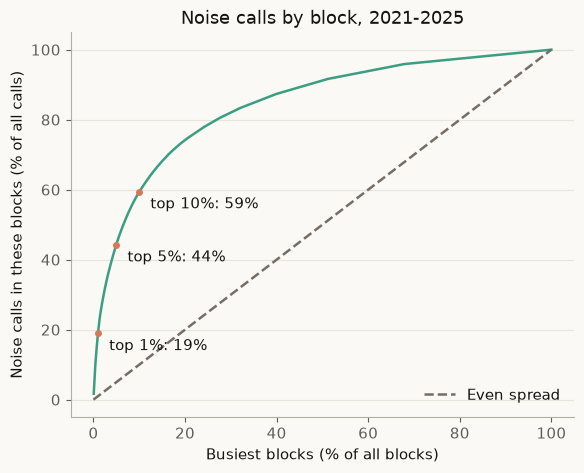

In [6]:
# Cumulative share of the calls against the share of the blocks, busiest
# block first; the dashed line is an even spread of the calls
block_share = pd.Series(range(1, len(blocks) + 1)) / len(blocks)
call_share = blocks.cumsum().to_numpy() / blocks.sum()

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(block_share * 100, call_share * 100, color=PALETTE[0])
ax.plot([0, 100], [0, 100], linestyle="--", color=PALETTE[5], label="Even spread")
for row in concentration.itertuples():
    ax.plot(row.fraction * 100, row.share * 100, "o", color=PALETTE[1])
    ax.annotate(
        f"top {row.fraction:.0%}: {row.share:.0%}",
        (row.fraction * 100, row.share * 100),
        xytext=(8, -12),
        textcoords="offset points",
    )
ax.set_xlabel("Busiest blocks (% of all blocks)")
ax.set_ylabel("Noise calls in these blocks (% of all calls)")
ax.set_title("Noise calls by block, 2021-2025")
ax.legend(loc="lower right")
fig.savefig(figures / "05_a8_concentration.png")